<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/trimsft_mathematical_reasoning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# [CELL 1 - Environment Setup & Imports]
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"TrimSFT Mathematical Reasoning Environment Initialized on: {device}")

TrimSFT Mathematical Reasoning Environment Initialized on: cuda


In [5]:
# [CELL 2 - TrimSFT Loss Function with Logit-Gap Gaussian Weighting]

class TrimSFTLoss(nn.Module):
    """
    Computes token-level Trimmed Logit-Gap SFT loss.
    Trims supervision from both easy (high logit gap) and hard (low/negative logit gap) tokens
    using a Gaussian weighting profile centered at margin m with bandwidth tau.
    """
    def __init__(self, margin: float = 2.0, bandwidth: float = 1.0, ignore_index: int = -100):
        super().__init__()
        self.margin = margin
        self.bandwidth = bandwidth
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        logits: (Batch_Size, Seq_Len, Vocab_Size)
        targets: (Batch_Size, Seq_Len)
        """
        B, S, V = logits.shape

        # Flatten for token-level processing
        flat_logits = logits.view(-1, V) # (B*S, V)
        flat_targets = targets.view(-1)  # (B*S,)

        # Mask out ignored tokens
        mask = (flat_targets != self.ignore_index)
        if not mask.any():
            return torch.tensor(0.0, device=logits.device, requires_grad=True), torch.tensor(0.0)

        valid_logits = flat_logits[mask]
        valid_targets = flat_targets[mask]

        # 1. Extract logits of the gold tokens
        gold_logits = valid_logits.gather(dim=-1, index=valid_targets.unsqueeze(-1)).squeeze(-1) # (N,)

        # 2. Find maximum competing non-gold logit
        # Mask out gold logits by setting them to a very low number
        logits_masked = valid_logits.clone()
        logits_masked.scatter_(dim=-1, index=valid_targets.unsqueeze(-1), value=-float('inf'))
        max_competitor_logits, _ = logits_masked.max(dim=-1) # (N,)

        # 3. Compute Logit Gap: Delta_t = z_gold - max(z_competitor)
        logit_gaps = gold_logits - max_competitor_logits

        # 4. Compute Gaussian weights w_t with stop-gradient (sg)
        # w_t = exp( - (Delta_t - m)^2 / (2 * tau^2) )
        weights = torch.exp(-((logit_gaps - self.margin) ** 2) / (2 * (self.bandwidth ** 2)))
        weights_detached = weights.detach() # Stop-gradient on weights

        # 5. Standard token-level cross entropy (unreduced)
        ce_loss = F.cross_entropy(valid_logits, valid_targets, reduction='none')

        # 6. Apply TrimSFT reweighting
        trimmed_loss = (weights_detached * ce_loss).mean()
        mean_weight = weights_detached.mean()

        return trimmed_loss, mean_weight

print("TrimSFTLoss Module Compiled Successfully.")

TrimSFTLoss Module Compiled Successfully.


In [8]:
# [CELL 3 - Verification Run with Synthetic Logits & Targets]

vocab_size = 1000
seq_len = 32
batch_size = 4

# Simulate model logits where gold tokens are partially learned (gaps around -2 to +6)
synthetic_logits = torch.randn(batch_size, seq_len, vocab_size, device=device)
synthetic_targets = torch.randint(0, vocab_size, (batch_size, seq_len), device=device)

# Boost gold logits slightly to simulate realistic intermediate training logit gaps
gold_indices = synthetic_targets.unsqueeze(-1)
synthetic_logits.scatter_add_(dim=-1, index=gold_indices, src=torch.ones_like(synthetic_logits) * 3.5)

trimsft_criterion = TrimSFTLoss(margin=2.0, bandwidth=1.2)
loss_val, avg_w = trimsft_criterion(synthetic_logits, synthetic_targets)

print("Synthetic Forward Verification Complete.")
print(f"TrimSFT Weighted Loss Value: {loss_val.item():.4f}")
print(f"Mean Token Weight (Retention): {avg_w.item():.4f}")

Synthetic Forward Verification Complete.
TrimSFT Weighted Loss Value: 1.3506
Mean Token Weight (Retention): 0.4264


In [3]:
# [CELL 4 - Simulating Logit-Gap Distribution Across Training Regimes]

# Generate synthetic logit gaps spanning from negative (hard/confused) to large positive (mastered)
simulated_gaps = np.linspace(-3.0, 8.0, 500)

# Gaussian weighting profile parameters
m = 2.0
tau = 1.2

weights_profile = np.exp(-((simulated_gaps - m) ** 2) / (2 * (tau ** 2)))

print(f"Logit gap simulation profile generated across {len(simulated_gaps)} evaluation points.")
print(f"Peak weight concentration centered at margin m = {m}, bandwidth tau = {tau}.")

Logit gap simulation profile generated across 500 evaluation points.
Peak weight concentration centered at margin m = 2.0, bandwidth tau = 1.2.


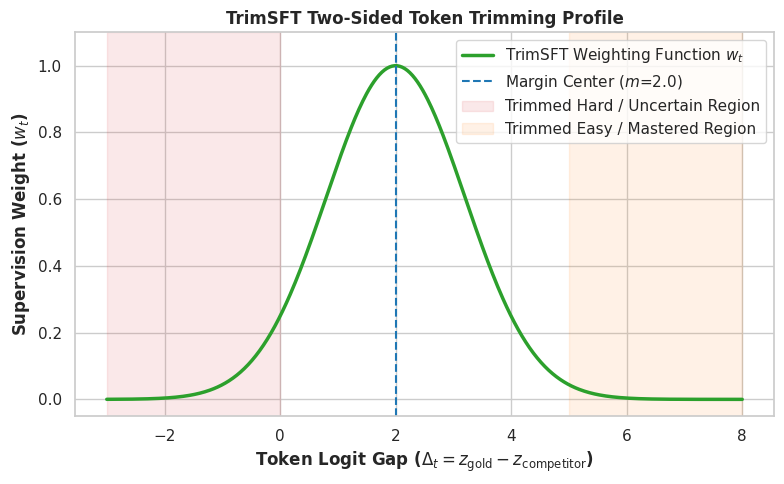

TrimSFT profile plot saved cleanly as trimsft_weighting_profile.png.


In [9]:
# [CELL 5 - Visualization of TrimSFT Two-Sided Trimming Profile]

plt.figure(figsize=(8, 5))
plt.plot(simulated_gaps, weights_profile, color='#2ca02c', lw=2.5, label=r'TrimSFT Weighting Function $w_t$')
plt.axvline(x=m, color='#1f77b4', linestyle='--', label=f'Margin Center ($m$={m})')
plt.axvspan(-3.0, 0.0, color='#d62728', alpha=0.1, label='Trimmed Hard / Uncertain Region')
plt.axvspan(5.0, 8.0, color='#ff7f0e', alpha=0.1, label='Trimmed Easy / Mastered Region')

plt.title("TrimSFT Two-Sided Token Trimming Profile", fontweight='bold')
plt.xlabel(r"Token Logit Gap ($\Delta_t = z_{\mathrm{gold}} - z_{\mathrm{competitor}}$)", fontweight='bold')
plt.ylabel(r"Supervision Weight ($w_t$)", fontweight='bold')
plt.ylim(-0.05, 1.1)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig("trimsft_weighting_profile.png", dpi=300)
plt.show()

print("TrimSFT profile plot saved cleanly as trimsft_weighting_profile.png.")